# Virtual occupancy sensing from CO2: walkthrough

MMA3001 project. A single-zone CO2 mass-balance model (physics) is inverted to
estimate room occupancy from a CO2 sensor and compared with machine-learning
regressors. This notebook runs top-to-bottom in under two minutes using
**synthetic rooms only** (known truth, no private data). Section 5 is an
optional real-data check that is skipped if `data/processed/rooms.parquet` is absent.

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | The forward model and three time-stepping schemes |
| 2 | Verification: observed convergence orders |
| 3 | Inverse problem: calibrate on 70 %, estimate occupancy on the last 30 % |
| 4 | Physics vs ML by blocked cross-validation |
| 5 | Optional: real data |
| 6 | Pointers to the full workflow |

## 0. Setup

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
try:
    import occupancy
    print("occupancy already importable from", pathlib.Path(occupancy.__file__).parent)
except ImportError:
    if IN_COLAB:
        # The repository is private, so `git clone` from Colab will not work.
        raise SystemExit(
            "Running on Colab and the `occupancy` package is not installed.\n"
            "Option A: upload the repository zip (Files panel), then run\n"
            "    !unzip -q mma3001_project.zip && pip install -q ./mma3001_project\n"
            "Option B: clone locally, then upload the folder and `pip install ./mma3001_project`.\n"
            "Re-run this cell afterwards (restart the runtime if prompted)."
        )
    # Local run: notebook lives in <repo>/notebooks, package source in <repo>/src
    for cand in (pathlib.Path("..") / "src", pathlib.Path("src")):
        if (cand / "occupancy").is_dir():
            sys.path.insert(0, str(cand.resolve()))
            break
    import occupancy
    print("occupancy imported from", pathlib.Path(occupancy.__file__).parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)

from occupancy.physics import RoomParams, simulate, calibrate, estimate_occupancy
from occupancy.synthetic import make_room
from occupancy.pipeline import prepare_room, run_room_cv

occupancy already importable from /home/user/mma3001_project/src/occupancy


## 1. The model

The room is one well-mixed control volume. Occupants generate CO2 and
ventilation exchanges room air with outdoor air:

$$V\,\frac{dC}{dt} = 10^{6}\, g\, N(t) - Q\,\bigl(C - C_{out}\bigr)$$

| Symbol | Meaning | Unit |
|---|---|---|
| $C$ | room CO2 concentration | ppm |
| $C_{out}$ | outdoor / supply CO2 | ppm |
| $V$ | effective room volume | m³ |
| $Q$ | outdoor-air flow rate | m³/s |
| $g$ | CO2 generation per person (sedentary adult, $5.2\times10^{-6}$) | m³/s/person |
| $N(t)$ | occupants (piecewise constant) | persons |

The time constant is $\tau = V/Q$ [s] and the steady state for constant $N$ is
$C_{ss} = C_{out} + 10^6 g N / Q$ [ppm]. Below: a 150 m³ room at 3 air changes
per hour, 8 people arriving at t = 0.5 h and leaving at t = 2.0 h. Explicit Euler
is deliberately run with a coarse 15 min step to make its error visible;
RK4 is run on the same grid; "exact" is the analytical solution per constant-$N$ interval.

tau = V/Q = 1200 s = 20 min,  ACH = 3.0 1/h
steady state with N = 8: 753 ppm


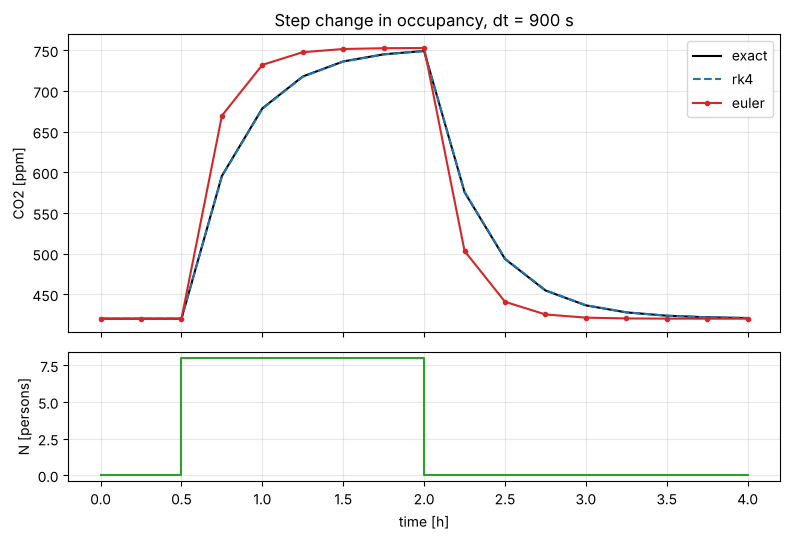

euler  max |error vs exact| =   74.004 ppm
rk4    max |error vs exact| =    0.584 ppm


In [2]:
p = RoomParams(V=150.0, Q=150.0 * 3 / 3600, C_out=420.0)   # V [m3], Q [m3/s], C_out [ppm]
print(f"tau = V/Q = {p.tau:.0f} s = {p.tau/60:.0f} min,  ACH = {p.ach:.1f} 1/h")
print(f"steady state with N = 8: {p.steady_state(8):.0f} ppm")

dt = 900.0                                    # step [s]
t = np.arange(0, 4 * 3600 + dt, dt)           # time [s]
N = np.where((t >= 0.5 * 3600) & (t < 2.0 * 3600), 8.0, 0.0)   # occupancy [persons]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.3]})
sols = {m: simulate(t, N, p, method=m) for m in ("exact", "rk4", "euler")}
for m, style in (("exact", "k-"), ("rk4", "C0--"), ("euler", "C3o-")):
    ax.plot(t / 3600, sols[m], style, ms=3, label=m)
ax.set_ylabel("CO2 [ppm]"); ax.legend(); ax.set_title(f"Step change in occupancy, dt = {dt:.0f} s")
ax2.step(t / 3600, N, where="post", color="C2"); ax2.set_ylabel("N [persons]"); ax2.set_xlabel("time [h]")
plt.tight_layout(); plt.show()
for m in ("euler", "rk4"):
    print(f"{m:6s} max |error vs exact| = {np.max(np.abs(sols[m] - sols['exact'])):8.3f} ppm")

## 2. Verification: convergence order

With constant occupancy the ODE has a closed-form solution, so the global error
at $t = 1$ h can be measured exactly. For a scheme of order $p$ the error scales
as $h^p$; the observed order is the slope of $\log(\text{error})$ against $\log h$.
Expected: about 1 for explicit Euler and 4 for classical RK4.

Observed orders (slope of log error vs log h, error at t = 1 h):
  euler   0.98   (theory 1)
  rk4     4.11   (theory 4)


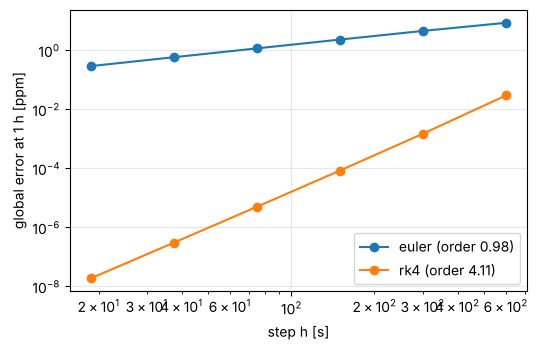

In [3]:
T, N0, C0 = 3600.0, 6.0, 420.0                    # horizon [s], occupancy [persons], C(0) [ppm]
C_exact = p.steady_state(N0) + (C0 - p.steady_state(N0)) * np.exp(-T / p.tau)   # [ppm]
hs = np.array([T / n for n in (6, 12, 24, 48, 96, 192)])                          # step [s]
errs = {m: [] for m in ("euler", "rk4")}
for h in hs:
    tt = np.arange(0, T + h / 2, h)
    for m in errs:
        C = simulate(tt, np.full_like(tt, N0), p, C0=C0, method=m)
        errs[m].append(abs(C[-1] - C_exact))

rows = {m: np.polyfit(np.log(hs), np.log(np.maximum(e, 1e-16)), 1)[0] for m, e in errs.items()}
print("Observed orders (slope of log error vs log h, error at t = 1 h):")
for m, order in rows.items():
    print(f"  {m:6s} {order:5.2f}   (theory {1 if m == 'euler' else 4})")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for m, e in errs.items():
    ax.loglog(hs, e, "o-", label=f"{m} (order {rows[m]:.2f})")
ax.set_xlabel("step h [s]"); ax.set_ylabel("global error at 1 h [ppm]"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Inverse problem on a synthetic room

`make_room` simulates a 28-day record with irregular sampling (mean 10 min),
sensor noise (15 ppm), 3 % dropouts and a random weekday schedule, so the
true $V$, $Q$, $C_{out}$ and $N(t)$ are known. `prepare_room` puts CO2 and
occupancy on a uniform 15 min grid.

The mass balance is linear in its unknowns, so the room parameters are fitted by
least squares on $N = a\,\dot C + b\,C + c$ over the first 70 % of the record
(`calibrate`). Occupancy is then recovered on the last 30 % by inverting the
model, $N = (V\,\dot C + Q\,(C - C_{out}))/(10^6 g)$, with a central finite-difference
derivative (`estimate_occupancy`). The assumed $g$ is the true one, so $V$ and $Q$
are identifiable only as $V/g$ and $Q/g$.

3953 irregular CO2 reports -> 2687 grid rows of 900 s
            V [m3]    Q [m3/s]  C_out [ppm]
true         150.0      0.1250        420.0
fitted       140.2      0.1223        419.1
hold-out: MAE = 0.23 persons, RMSE = 0.40 persons (745 grid points)


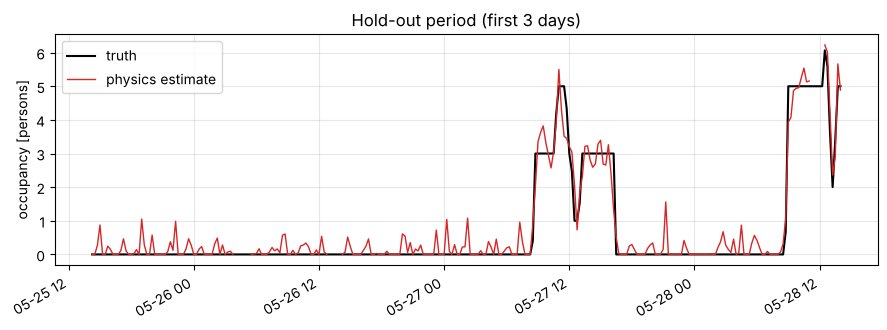

In [4]:
env, occ, p_true = make_room(days=28, seed=1)
table = prepare_room(env, occ)                    # 15-min grid; co2_ppm [ppm], occupancy [persons]
dt = 900.0                                        # grid spacing [s]
print(f"{len(env)} irregular CO2 reports -> {len(table)} grid rows of {dt:.0f} s")

n_fit = int(0.7 * len(table))
fit, test = table.iloc[:n_fit], table.iloc[n_fit:]
p_hat = calibrate(fit["co2_ppm"].to_numpy(), fit["occupancy"].to_numpy(), dt)

print(f"{'':8s}{'V [m3]':>10s}{'Q [m3/s]':>12s}{'C_out [ppm]':>13s}")
print(f"{'true':8s}{p_true.V:10.1f}{p_true.Q:12.4f}{p_true.C_out:13.1f}")
print(f"{'fitted':8s}{p_hat.V:10.1f}{p_hat.Q:12.4f}{p_hat.C_out:13.1f}")

N_hat = estimate_occupancy(test["co2_ppm"].to_numpy(), dt, p_hat)     # [persons]
N_true = test["occupancy"].to_numpy()
ok = np.isfinite(N_hat) & np.isfinite(N_true)
print(f"hold-out: MAE = {np.mean(np.abs(N_hat[ok] - N_true[ok])):.2f} persons, "
      f"RMSE = {np.sqrt(np.mean((N_hat[ok] - N_true[ok])**2)):.2f} persons "
      f"({ok.sum()} grid points)")

sl = test.iloc[: 3 * 96]                          # first 3 days of the hold-out
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(sl.index, sl["occupancy"], "k-", label="truth")
ax.plot(sl.index, N_hat[: len(sl)], "C3-", lw=1, label="physics estimate")
ax.set_ylabel("occupancy [persons]"); ax.set_title("Hold-out period (first 3 days)"); ax.legend()
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 4. Physics vs machine learning

`run_room_cv` runs blocked leave-one-week-out cross-validation: each 7-day block
is predicted by models trained on the other blocks, with a 1-day buffer either side
to prevent leakage through lagged features. Pooled out-of-fold scores are returned.
Compared: a time-of-week baseline that uses no sensor data, the calibrated physics
inversion, ridge regression (`linear`), random forest (`forest`), an MLP, and
`+phys` hybrids that add the physics estimate as a feature. MAE and RMSE in persons;
F1 and accuracy are for occupied/vacant (more than 0.5 persons). Only three learners
are used here to keep the runtime low.

In [5]:
scores, oof = run_room_cv(table, dt, models=("linear", "forest", "mlp"))
scores[["mae", "rmse", "r2", "f1", "fit_s", "folds"]].round(3)

,mae,rmse,r2,f1,fit_s,folds
model,,,,,,
time_of_week,0.585,1.377,0.557,0.930,0.001,4
physics,0.240,0.432,0.957,0.883,0.013,4
linear,0.293,0.509,0.941,0.827,0.004,4
forest,0.173,0.447,0.954,0.966,0.472,4
forest+phys,0.134,0.371,0.969,0.979,0.442,4
mlp,0.180,0.414,0.961,0.977,0.488,4
mlp+phys,0.160,0.368,0.969,0.978,0.347,4


## 5. Optional: real data

The real MSI data are private and not in the repository (see `data/README.md`
for how to obtain and ingest them). If `data/processed/rooms.parquet` exists, the
cell below scores the primary room with blocked cross-validation (ridge and forest
only); otherwise it prints a note and does nothing.

In [6]:
rooms_path = next((q for q in (pathlib.Path("../data/processed/rooms.parquet"),
                               pathlib.Path("data/processed/rooms.parquet")) if q.exists()), None)
if rooms_path is None:
    print("Real data not found (data/processed/rooms.parquet) -- skipping this section.")
    print("See data/README.md for how to obtain the MSI files and run `make ingest`.")
else:
    df = pd.read_parquet(rooms_path)
    name = next(r for r in df["room"].unique() if "primary" in r)
    real = df[df["room"] == name].drop(columns="room").asfreq("15min")
    dt_real = 900.0
    real_scores, _ = run_room_cv(real, dt_real, models=("linear", "forest"))
    print(f"primary room: {len(real)} grid rows of 15 min ({len(real) * 0.25 / 24:.0f} days incl. gaps)")
    display(real_scores[["mae", "rmse", "r2", "f1", "folds"]].round(3))

primary room: 10127 grid rows of 15 min (105 days incl. gaps)


,mae,rmse,r2,f1,folds
model,,,,,
time_of_week,2.174,3.065,-0.004,0.853,7
physics,1.554,2.238,0.465,0.822,7
linear,1.578,2.251,0.459,0.860,7
forest,1.429,2.116,0.522,0.866,7
forest+phys,1.433,2.135,0.513,0.870,7


## 6. Going further

Full workflow (Makefile targets, run from the repository root; `make help` lists all):

| Target | What it does | Needs data |
|---|---|---|
| `make test` | pytest suite | no |
| `make experiment-synthetic` | all models on four manufactured rooms | no |
| `make profile` | runtime/performance profile | no |
| `make ingest` | raw MSI exports to `data/processed/*.parquet` | raw data |
| `make experiment` | synthetic then real-room comparison | yes |
| `make sensitivity` | sensitivity studies (synthetic and real) | partly |
| `make figures` | report figures | yes |

Methods, results and limitations are in `reports/report.md`; the repository
overview and key results are in `README.md`.